# Claim-cost discovery: seven libraries, each driven by an agent analyst

This benchmark asks what an analyst learns about a dataset with each of seven
modelling libraries, and how well what it learns matches the truth. The data
are the 20,640 real 1990 California census block groups, with a claim-cost
outcome simulated from a known formula, so every claim an analysis makes can
be checked: which covariates move the expected cost, which pairs interact,
what drives the spread, how large each effect is, and how wide a prediction
interval must be. Each library was used by its own analyst, a Claude Haiku
agent that received the same written brief and worked without help. Each
analyst delivered a pipeline script, which the grader then re-ran, unseen,
on twelve further draws of the problem: eight with new noise, two in which
the outcome is unrelated to every covariate, and two with only 800 training
rows. The scores below are therefore scores of the pipeline each analyst
built with its library, measured on data it never saw.

The libraries are mboostrs, XGBoost, LightGBM, CatBoost, the Explainable
Boosting Machine from InterpretML, pyGAM and statsmodels. The scoring follows
the knowledge-discovery scorecard in `docs/scorecard/scorecard.md`: six of
its ten dimensions are measured with thresholds fixed before any analyst
started, and four are judged from the analysts' reports, friction logs and
code, with the evidence quoted.

In [1]:
import json
import sys
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from great_tables import GT, loc, style
from IPython.display import Markdown, display

ROOT = Path("claims_discovery")
sys.path.insert(0, str(ROOT))
import grade  # noqa: E402  (the pre-registered grader, docs/book/benchmarks/claims_discovery/grade.py)

LIBS = {
    "mboostrs": "mboostrs 0.1.3",
    "xgboost": "XGBoost 3.4.0",
    "lightgbm": "LightGBM 4.7.0",
    "catboost": "CatBoost 1.2.10",
    "ebm": "InterpretML EBM 0.7.8",
    "pygam": "pyGAM 0.12.0",
    "statsmodels": "statsmodels 0.15.0",
}
REPS = ["dev"] + [f"H{i}" for i in range(1, 9)] + ["N1", "N2", "S1", "S2"]

graded = [grade.grade_library(ROOT, lib, REPS) for lib in LIBS]
disc = pl.concat([g["discovery"] for g in graded], how="diagonal_relaxed")
queries = pl.concat([g["queries"] for g in graded], how="diagonal_relaxed")
preds = pl.concat([g["predictions"] for g in graded], how="diagonal_relaxed")
runlogs = {lib: json.loads((ROOT / "eval" / lib / "runlog.json").read_text()) for lib in LIBS}
agents = pl.read_csv(ROOT / "agents.csv")
JUDGED = json.loads((ROOT / "judged_scores.json").read_text())
dims = ["D1", "D2", "D3", "D4", "D5", "D6", "D7", "D8", "D9", "D10"]
names = {"D1": "Relationship discovery", "D2": "Causal humility", "D3": "Explanation quality",
         "D4": "Importance quantification", "D5": "Iteration speed", "D6": "Robustness",
         "D7": "Human-friendliness", "D8": "Agent-friendliness", "D9": "Uncertainty honesty",
         "D10": "Reproducibility"}

The table compares every library on the headline measurements. Discovery
columns count claims against the planted structure; the effect-query columns
score the eight average contrasts the brief asked for; the prediction
columns score 90% intervals for new observations on test rows whose income
distribution is shifted upward from training.

In [2]:
# Scores use the hidden replicates only; dev is the replicate the analysts saw.
HIDDEN = [f"H{i}" for i in range(1, 9)]
full = disc.filter(pl.col("rep").is_in(HIDDEN))
small = disc.filter(pl.col("kind") == "small")
null = disc.filter(pl.col("kind") == "null")
q_full = queries.filter(pl.col("rep").is_in(HIDDEN))
p_full = preds.filter(pl.col("rep").is_in(HIDDEN))
quartiles = [f"cov_hh_q{k}" for k in range(1, 5)]


def failures(lib):
    return sum(1 for rep in REPS if not runlogs[lib].get(rep, {}).get("ok", False))


ok_runs = disc.select("library", "rep", "ok")
q_full = q_full.join(ok_runs, on=["library", "rep"])
p_full = p_full.with_columns(pl.col("ok").fill_null(False))

rows = []
for lib in LIBS:
    # The headline describes completed runs; failed runs are counted in the
    # last column and penalized in the scorecard as the protocol specifies.
    f = full.filter((pl.col("library") == lib) & pl.col("ok"))
    s = small.filter((pl.col("library") == lib) & pl.col("ok"))
    n = null.filter(pl.col("library") == lib)
    q = q_full.filter((pl.col("library") == lib) & pl.col("ok"))
    p = p_full.filter((pl.col("library") == lib) & pl.col("ok"))
    has_pi = p["has_pi"].fill_null(False).all() if p.height else False
    rows.append({
        "library": LIBS[lib],
        "mean_tpr": f["mean_tpr"].mean(),
        "mean_fdr": f["mean_fdr"].mean(),
        "pair_tpr": f["pair_tpr"].mean(),
        "scale_tpr": f["scale_tpr"].mean(),
        # A crashed null run made no claims because it made nothing; it is
        # counted under "Failed runs", not as a clean null result.
        "null_false": n.filter(pl.col("ok"))["n_false"].mean() if n["ok"].all() else None,
        "small_fdr": s["mean_fdr"].mean(),
        "q_cov": q["covered"].mean(),
        "q_rmse": float(np.sqrt(np.nanmean(np.square(q["error"].fill_null(np.nan).to_numpy())))),
        "pi_cov": p["cov90"].mean() if has_pi else None,
        "pi_worst_q": min(p[c].mean() for c in quartiles) if has_pi else None,
        "winkler": p["winkler"].mean() if has_pi else None,
        "rmse_f": p["rmse_f"].mean(),
        "failed": failures(lib),
    })
headline = pl.DataFrame(rows)

In [3]:
def best(col, rule="min"):
    values = headline[col].to_numpy().astype(float)
    if rule == "max":
        target = np.nanmax(values)
    elif rule == "nominal":
        target = values[np.nanargmin(np.abs(values - 0.90))]
    else:
        target = np.nanmin(values)
    return [i for i, v in enumerate(values) if np.isfinite(v) and abs(v - target) < 1e-9]


table = (
    GT(headline, rowname_col="library")
    .tab_header(
        title="Seven libraries, each run by an agent analyst, on a planted-truth claim-cost problem",
        subtitle="Means over 8 hidden replicates (null and small-n columns: 2 replicates each). "
                 "Rates in [0, 1]; RMSE and interval score in units of y (log claim-cost index).",
    )
    .tab_spanner("Discovery", ["mean_tpr", "mean_fdr", "pair_tpr", "scale_tpr", "null_false", "small_fdr"])
    .tab_spanner("Effect queries", ["q_cov", "q_rmse"])
    .tab_spanner("Prediction", ["pi_cov", "pi_worst_q", "winkler", "rmse_f"])
    .cols_label(
        mean_tpr="Main effects found", mean_fdr="False share", pair_tpr="Interactions found",
        scale_tpr="Spread driver found", null_false="False claims, null data",
        small_fdr="False share, n=800", q_cov="90% coverage", q_rmse="RMSE",
        pi_cov="90% coverage", pi_worst_q="Worst quartile", winkler="Interval score",
        rmse_f="RMSE vs true mean", failed="Failed runs",
    )
    .fmt_number(["mean_tpr", "mean_fdr", "pair_tpr", "scale_tpr", "small_fdr", "q_cov",
                 "pi_cov", "pi_worst_q"], decimals=2)
    .fmt_number(["null_false"], decimals=1)
    .fmt_number(["q_rmse", "winkler", "rmse_f"], decimals=3)
    .sub_missing(missing_text="failed")
    .tab_source_note(
        "Every column except Failed runs averages the runs that completed; a failed run "
        "(crash or 10-minute timeout) is counted in Failed runs and penalized in the scorecard "
        "as the protocol specifies. 'failed' marks a column with no completed run.")
    .tab_source_note(
        "Main effects found: share of the 6 covariates with a planted mean effect that the "
        "pipeline claimed. False share: claimed mean effects that have no planted effect, as a "
        "share of all claimed. Interactions found: share of the 2 planted pairs claimed. Spread "
        "driver found: whether households was claimed as a driver of spread.")
    .tab_source_note(
        "False claims, null data: mean number of mean effects, interactions and spread drivers "
        "claimed when y is unrelated to every covariate. Effect queries: 8 average contrasts per "
        "replicate; coverage is the share of 90% intervals containing the true contrast (64 per "
        "library), and a missing or zero-width interval that misses counts as not covering.")
    .tab_source_note(
        "Prediction: 90% intervals for a new observation on 5,160 income-shifted test rows. "
        "Worst quartile: the lowest coverage among the four quartiles of households, the variable "
        "that drives the spread. Interval score: Winkler score at alpha = 0.1 (width plus 20 times "
        "each miss; lower is better). An oracle with the true mean and spread scores coverage 0.90 "
        "in every quartile. Bold marks the best value in each column; coverage is best nearest 0.90.")
)
for col, rule in [("mean_tpr", "max"), ("mean_fdr", "min"), ("pair_tpr", "max"),
                  ("scale_tpr", "max"), ("null_false", "min"), ("small_fdr", "min"),
                  ("q_cov", "nominal"), ("q_rmse", "min"), ("pi_cov", "nominal"),
                  ("pi_worst_q", "nominal"), ("winkler", "min"), ("rmse_f", "min")]:
    table = table.tab_style(style.text(weight="bold"), loc.body(columns=col, rows=best(col, rule)))
table

GT(_tbl_data=shape: (7, 14)
┌─────────────────┬──────────┬──────────┬──────────┬───┬────────────┬──────────┬──────────┬────────┐
│ library         ┆ mean_tpr ┆ mean_fdr ┆ pair_tpr ┆ … ┆ pi_worst_q ┆ winkler  ┆ rmse_f   ┆ failed │
│ ---             ┆ ---      ┆ ---      ┆ ---      ┆   ┆ ---        ┆ ---      ┆ ---      ┆ ---    │
│ str             ┆ f64      ┆ f64      ┆ f64      ┆   ┆ f64        ┆ f64      ┆ f64      ┆ i64    │
╞═════════════════╪══════════╪══════════╪══════════╪═══╪════════════╪══════════╪══════════╪════════╡
│ mboostrs 0.1.3  ┆ 1.0      ┆ 0.020408 ┆ 0.928571 ┆ … ┆ 0.899967   ┆ 2.005493 ┆ 0.055003 ┆ 3      │
│ XGBoost 3.4.0   ┆ 1.0      ┆ 0.053571 ┆ 0.25     ┆ … ┆ 0.884054   ┆ 2.030692 ┆ 0.085422 ┆ 0      │
│ LightGBM 4.7.0  ┆ 0.979167 ┆ 0.0      ┆ 0.4375   ┆ … ┆ 0.891063   ┆ 2.05298  ┆ 0.080015 ┆ 0      │
│ CatBoost 1.2.10 ┆ 1.0      ┆ 0.053571 ┆ 0.0625   ┆ … ┆ 0.892621   ┆ 2.021608 ┆ 0.083191 ┆ 0      │
│ InterpretML EBM ┆ 0.916667 ┆ 0.0      ┆ 0.6875   ┆ … ┆ 0.895931   ┆ 2.021907 ┆ 0.068633 ┆ 0      │
│ 0.7.8           ┆          ┆          ┆          ┆   ┆            ┆          ┆          ┆        │
│ pyGAM 0.12.0    ┆ 1.0      ┆ 0.0      ┆ 0.375    ┆ … ┆ 0.89116    ┆ 2.02041  ┆ 0.075374 ┆ 0      │
│ statsmodels     ┆ 0.979167 ┆ 0.208631 ┆ 0.0625   ┆ … ┆ 0.898364   ┆ 2.031292 ┆ 0.088521 ┆ 0      │
│ 0.15.0          ┆          ┆          ┆          ┆   ┆            ┆          ┆          ┆        │
└─────────────────┴──────────┴──────────┴──────────┴───┴────────────┴──────────┴──────────┴────────┘, _body=<great_tables._gt_data.Body object at 0x10dc5b4a0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='mean_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='Main effects found', column_align='right', column_width=None), ColInfo(var='mean_fdr', type=<ColInfoTypeEnum.default: 1>, column_label='False share', column_align='right', column_width=None), ColInfo(var='pair_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='Interactions found', column_align='right', column_width=None), ColInfo(var='scale_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='Spread driver found', column_align='right', column_width=None), ColInfo(var='null_false', type=<ColInfoTypeEnum.default: 1>, column_label='False claims, null data', column_align='right', column_width=None), ColInfo(var='small_fdr', type=<ColInfoTypeEnum.default: 1>, column_label='False share, n=800', column_align='right', column_width=None), ColInfo(var='q_cov', type=<ColInfoTypeEnum.default: 1>, column_label='90% coverage', column_align='right', column_width=None), ColInfo(var='q_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None), ColInfo(var='pi_cov', type=<ColInfoTypeEnum.default: 1>, column_label='90% coverage', column_align='right', column_width=None), ColInfo(var='pi_worst_q', type=<ColInfoTypeEnum.default: 1>, column_label='Worst quartile', column_align='right', column_width=None), ColInfo(var='winkler', type=<ColInfoTypeEnum.default: 1>, column_label='Interval score', column_align='right', column_width=None), ColInfo(var='rmse_f', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE vs true mean', column_align='right', column_width=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='Failed runs', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dbf6720>, _spanners=Spanners([SpannerInfo(spanner_id='Discovery', spanner_level=0, spanner_label='Discovery', spanner_units=None, spanner_pattern=None, vars=['mean_tpr', 'mean_fdr', 'pair_tpr', 'scale_tpr', 'null_false', 'small_fdr'], built=None), SpannerInfo(spanner_id='Effect queries', spanner_level=0, spanner_label='Effect queries', spanner_units=None, spanner_pattern=None, vars=['q_cov', 'q_rmse'], built=None), SpannerInfo(spanner_id='Prediction', spanner_level=0, spanner_label='Pre

## The experiment setting

**Covariates.** The 20,640 block groups of the 1990 California census
(`docs/book/case_studies/california_housing_1990.csv`): longitude, latitude,
median housing age, total rooms, total bedrooms, population, households,
median income and median house value, plus the per-household ratios
`ave_rooms`, `ave_bedrooms` and `ave_occup`. One categorical covariate,
`roof_class` (A–D), is simulated; older housing stock and the north carry
more C and D roofs, so it is correlated with age and latitude. Several
covariates are strongly collinear (households, population, total rooms and
total bedrooms correlate above 0.85), `ave_occup` has extreme values (up to
1,243 persons per household), and housing age is capped at 52 by the census.

**Outcome.** `y`, a log claim-cost index, is the planted mean plus
heavy-tailed noise (Student-t, 5 degrees of freedom). Its noise standard
deviation falls with the number of households, as an average over more
policies would. The planted mean explains about 42% of the variance of `y`.

**Missing values and shift.** Housing age is missing for 4% of block groups
in the south and 16% in the north (missing at random given latitude), and
the bedroom columns for 1% at random; the missing cells are redrawn in every
replicate. The test rows (25%) are drawn with probability rising in income,
so test median income is 4.5 against 3.6 in training.

**Replicates.** The analysts saw only the dev replicate: training rows with
`y`, test rows without. The grader re-ran every pipeline on twelve hidden
replicates generated by the same code (`claims_discovery/prepare.py`): H1–H8
redraw the noise and the missing cells; N1–N2 replace `y` by noise with no
relation to any covariate and constant spread; S1–S2 keep only 800 training
rows. The covariates and the train/test split are the same in every
replicate.

In [4]:
key = json.loads((ROOT / "truth" / "key.json").read_text())
planted = pl.DataFrame([
    {"structure": "Mean effect", "covariate": "median_income", "form": "-0.45 log(income / 3.5): decreasing, steepest at low income"},
    {"structure": "Mean effect", "covariate": "housing_median_age", "form": "+0.30 step centred at 35 years (logistic, scale 2.5)"},
    {"structure": "Mean effect", "covariate": "ave_occup", "form": "+0.35 log(occupancy / 3), occupancy clipped to [1, 6]: increasing, flat above 6"},
    {"structure": "Mean effect", "covariate": "roof_class", "form": "A 0, B 0, C +0.15, D +0.35"},
    {"structure": "Mean effect", "covariate": "latitude, longitude", "form": "two Gaussian bumps: +0.45 near (34.2, -117.4), +0.35 near (39.0, -121.0)"},
    {"structure": "Interaction", "covariate": "latitude x longitude", "form": "the bumps are not additive in the two coordinates"},
    {"structure": "Interaction", "covariate": "housing_median_age x median_income", "form": "+0.30 extra for old stock (age > 35) in low-income areas (income < 3)"},
    {"structure": "Spread", "covariate": "households", "form": "sd = 0.12 + 0.30 sqrt(400 / max(households, 20)); Student-t noise, 5 df"},
    {"structure": "No effect", "covariate": "total_rooms, total_bedrooms, population, households (mean), median_house_value, ave_rooms, ave_bedrooms", "form": "absent from the mean; median_house_value correlates -0.28 with y through income"},
])
GT(planted).tab_header(title="The planted structure (hidden from the analysts)",
                       subtitle="y is a log claim-cost index; its variance explained by the mean is about 0.42") \
    .cols_label(structure="Kind", covariate="Covariate(s)", form="Form")

GT(_tbl_data=shape: (9, 3)
┌─────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ structure   ┆ covariate                       ┆ form                            │
│ ---         ┆ ---                             ┆ ---                             │
│ str         ┆ str                             ┆ str                             │
╞═════════════╪═════════════════════════════════╪═════════════════════════════════╡
│ Mean effect ┆ median_income                   ┆ -0.45 log(income / 3.5): decre… │
│ Mean effect ┆ housing_median_age              ┆ +0.30 step centred at 35 years… │
│ Mean effect ┆ ave_occup                       ┆ +0.35 log(occupancy / 3), occu… │
│ Mean effect ┆ roof_class                      ┆ A 0, B 0, C +0.15, D +0.35      │
│ Mean effect ┆ latitude, longitude             ┆ two Gaussian bumps: +0.45 near… │
│ Interaction ┆ latitude x longitude            ┆ the bumps are not additive in … │
│ Interaction ┆ housing_median_age x median_in… ┆ +0.30 extra for old stock (age… │
│ Spread      ┆ households                      ┆ sd = 0.12 + 0.30 sqrt(400 / ma… │
│ No effect   ┆ total_rooms, total_bedrooms, p… ┆ absent from the mean; median_h… │
└─────────────┴─────────────────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10c3afaa0>, _boxhead=Boxhead([ColInfo(var='structure', type=<ColInfoTypeEnum.default: 1>, column_label='Kind', column_align='left', column_width=None), ColInfo(var='covariate', type=<ColInfoTypeEnum.default: 1>, column_label='Covariate(s)', column_align='left', column_width=None), ColInfo(var='form', type=<ColInfoTypeEnum.default: 1>, column_label='Form', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dc93890>, _spanners=Spanners([]), _heading=Heading(title='The planted structure (hidden from the analysts)', subtitle='y is a log claim-cost index; its variance explained by the mean is about 0.42', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dc93d40>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10dc92990>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10c3d1130>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2

**Analysts.** Seven Claude Haiku agents, one per library, launched at the
same time in the background on one 10-core machine. Each received the brief
below word for word and a short assignment naming its library, its run
directory and the documentation it could use, and worked without any
further input. The coordinator (Claude Opus, which wrote the brief, the
generator and the grader) did not see any analyst's work until it finished.
All analysts used the same Python environment; while developing they were
asked to cap themselves at 2 threads because they shared the machine.

**Execution and timing.** The grader ran each delivered `run.py` on the dev
replicate and the twelve hidden ones with seed 1, 4 threads and a 10-minute
limit per run, up to four libraries at a time. It then reran the dev
replicate to check reproducibility, called each analyst's `refit.py` ten
times (dropping one covariate each time) to time follow-up refits, and fitted
the final configuration once to 500,000 rows resampled from the dev training
rows. The follow-up and 500,000-row timings ran one library at a time with
nothing else on the machine.

**Pre-registration.** The protocol (`claims_discovery/PROTOCOL.md`) and the
generator were written and hashed before any analyst started, at
2026-10-09 23:38 UTC:

| File | sha256 |
|---|---|
| `PROTOCOL.md` | `0c28dca093c3e29526925531561f6c97e89828ce6d973936aa943a1a8d1fb30a` |
| `prepare.py` | `b0efd1041b6b7b3438bc184c7d5371b328b01e94028d51a54791c2f934ab89f6` |

Both files are published unchanged. `prepare.py` reads
`california_housing_1990.csv` from its own directory; copy it from
`docs/book/case_studies/` to regenerate every replicate. The grader that
scores the outputs is `claims_discovery/grade.py`; it differs from the
pre-registered version only in reading the households column for the
coverage-by-quartile check from the slimmed truth files published here.

## Guidance given to the analysts

Every analyst received the brief below, word for word, followed by the
assignment that follows it. Paths in both have been made relative to the
repository for publication; the analysts saw absolute paths to the same
files.

In [5]:
display(Markdown((ROOT / "BRIEF.md").read_text()))

# Analyst brief: what drives the claim-cost index?

You are the analyst for one modelling library (named in your assignment). Several
analysts receive this same brief, each with a different library, and work
independently. Do the best analysis your library allows, as a careful applied
statistician would.

## Data

`data/dev/train.parquet` (15,480 rows) and `data/dev/test.parquet` (5,160 rows,
no `y`). One row is a 1990 California census block group.

| Column | Meaning |
|---|---|
| `row_id` | Row identifier (not a covariate) |
| `longitude`, `latitude` | Block-group centroid |
| `housing_median_age` | Median age of the housing stock, years (has missing values) |
| `total_rooms`, `total_bedrooms` | Totals over the block group (`total_bedrooms` has missing values) |
| `population`, `households` | Counts |
| `median_income` | Median household income, tens of thousands of dollars |
| `median_house_value` | Median house value, dollars |
| `ave_rooms`, `ave_bedrooms`, `ave_occup` | Per-household averages (rooms, bedrooms, persons) |
| `roof_class` | Insurer's roof classification, `A`–`D` (string) |
| `y` | Log claim-cost index for the block group (already on a log scale; can be negative) |

The covariates are real census data, apart from `roof_class`. The outcome `y`
is simulated from a process that is hidden from you. Treat it as a real
business question. The test rows are a later book of business and are not a
random sample of the training rows.

## Questions from the business

1. Which covariates are associated with the expected claim-cost index, and
   what is the shape of each association?
2. Does the effect of any covariate depend on the value of another covariate?
3. Is the spread of `y` around its expected value the same everywhere? If not,
   what drives it?
4. The pricing team proposes a surcharge for block groups with high
   `median_house_value`, on the grounds that "expensive areas cost more". Does
   the data support `median_house_value` as a driver of claim cost?
5. Predict `y` for every test row, with a 90% prediction interval for a new
   observation of that row.

## Effect queries

For each query, report the average change in the expected value of `y` when
the named covariate(s) are moved from the first value to the second for every
training row, with all other columns held at their observed values. Give a
point estimate and a 90% interval for that average change.

| Id | Change |
|---|---|
| Q1 | `median_income` 2.5 → 6.0 |
| Q2 | `housing_median_age` 20 → 45 |
| Q3 | `ave_occup` 2.0 → 4.0 |
| Q4 | `roof_class` A → D |
| Q5 | `ave_rooms` 4.0 → 7.0 |
| Q6 | (`latitude`, `longitude`) (37.8, −122.3) → (34.2, −117.4) |
| Q7 | `households` 300 → 1200 |
| Q8 | `median_house_value` 150,000 → 350,000 |

## Deliverables (all in your run directory)

1. **`run.py`** — the whole pipeline, run as
   `python run.py --train TRAIN --test TEST --out OUTDIR --seed SEED`.
   It reads only the two files it is given, makes every modelling decision
   from that data (variable selection, tuning, interaction and spread
   checks), and writes `OUTDIR/findings.json` and `OUTDIR/predictions.parquet`.
   It will be re-run, unattended, on other draws of this problem: some with
   different noise, some with only 800 training rows, and some where `y` may
   have no relationship with any covariate. Do not hard-code findings.
   It must finish within 10 minutes with 4 CPU threads.
2. **`findings.json`** — schema below.
3. **`predictions.parquet`** — columns `row_id`, `mean`, `lower90`, `upper90`,
   one row per test row.
4. **`refit.py`** — defines
   `fit_predict(train: polars.DataFrame, test: polars.DataFrame, drop: list[str]) -> numpy.ndarray`,
   which fits your final model configuration (no tuning) without the columns
   in `drop` and returns mean predictions for `test`. It is used to time
   follow-up refits.
5. **`REPORT.md`** — a report for the business, at most 900 words, from your
   dev-data run: answers to questions 1–4, how sure you are of each finding,
   what the data cannot tell, and what you would check next.
6. **`tuning_log.csv`** — one row per configuration you tried, with its
   settings, the validation score and whether it was kept.
7. **`FRICTION.md`** — every point where the library made the task harder.
   Quote each library error or warning message you met verbatim, and say
   whether the message told you how to fix the problem.
8. Run `run.py` on the dev data with `--seed 1 --out dev_out` and keep the
   outputs.

### `findings.json` schema

```json
{
  "library": "name and version",
  "mean_effects": [
    {"variable": "median_income", "shape": "decreasing", "evidence": "one line"}
  ],
  "interactions": [
    {"variables": ["a", "b"], "evidence": "one line"}
  ],
  "variance_drivers": [
    {"variable": "x", "direction": "increases_spread", "evidence": "one line"}
  ],
  "effect_queries": {
    "Q1": {"estimate": -0.1, "lower90": -0.2, "upper90": 0.0}
  },
  "warnings": ["anything the pipeline found that a reader should know"]
}
```

- `mean_effects` lists only the covariates you conclude are associated with
  the expected value. `shape` is one of `increasing`, `decreasing`,
  `u_shaped`, `inverted_u`, `threshold_increase`, `threshold_decrease`,
  `nonmonotone`, `categorical`, `spatial`.
- `interactions` lists only pairs you conclude interact.
- `variance_drivers` lists only covariates you conclude change the spread;
  `direction` is `increases_spread`, `decreases_spread` or `nonmonotone`.
- Every query Q1–Q8 must appear. Use `null` for an interval bound you cannot
  produce.

## Rules

- Use the library you are assigned for the modelling. NumPy, Polars, pandas
  and SciPy may be used for data handling and for simple arithmetic around the
  model; another modelling library may not.
- Documentation: the library's docstrings (`help()`), its installed source
  code, and its official documentation. Do not read anything else in this
  repository, apart from the paths named in your assignment.
- Budget: at most 40 configurations in `tuning_log.csv`.
- Python: `source .venv/bin/activate`.
  Other analysts share the machine: export `OMP_NUM_THREADS=2` and
  `RAYON_NUM_THREADS=2` while developing, and do not start more than one
  long-running process at a time.
- Graders will score: discovery of the true structure (and absence of false
  claims, including on draws with no structure), accuracy and coverage of the
  effect-query intervals, accuracy and coverage of the prediction intervals
  (overall and within subgroups), the report, reproducibility of `run.py`,
  and the time taken by follow-up refits.


In [6]:
display(Markdown((ROOT / "ASSIGNMENT.md").read_text()))

# Analyst assignment

Each analyst was a Claude Haiku agent launched once, in the background, with
the message below and no further help. The only parts that changed between
analysts were the library name and version, the run directory, and the
documentation source shown in the table. All seven also received `BRIEF.md`
word for word.

## Message template

> Assignment: you are the analyst for the library **{LIBRARY}** (Python package `{PACKAGE}`, version {VERSION}{EXTRA}).
>
> Read the brief at docs/book/benchmarks/claims_discovery/BRIEF.md and carry it out completely. Your run directory is docs/book/benchmarks/claims_discovery/runs/{RUN_DIR}/ — write every deliverable there. The data is in docs/book/benchmarks/claims_discovery/data/dev/.
>
> Documentation you may use for {LIBRARY}: {DOCS}. Do not read anything else in the repository, and do not read any other analyst's run directory.
>
> Work on your own, without asking questions; nobody will answer. Deliver all eight items in the brief. Before you finish, confirm that `python run.py --train <dev train> --test <dev test> --out dev_out --seed 1` runs from your run directory and writes findings.json and predictions.parquet, and that refit.py imports and runs. Your final message: a short list of the deliverables written, the final model, and anything you could not complete.

## Per-library values

| Library | Package, version | Extra text | Documentation allowed |
|---|---|---|---|
| mboostrs | `mboostrs` 0.1.3 | — | `help()`, installed source (`python/mboostrs/`), and the book at `docs/book/` (usage/, methodology/, appendix/, case_studies/); docs/book/benchmarks/ and docs/book/cases/ excluded |
| XGBoost | `xgboost` 3.4.0 | — | `help()`, installed source, https://xgboost.readthedocs.io/ |
| LightGBM | `lightgbm` 4.7.0 | — | `help()`, installed source, https://lightgbm.readthedocs.io/ |
| CatBoost | `catboost` 1.2.10 | — | `help()`, installed source, https://catboost.ai/docs/ |
| InterpretML EBM | `interpret` 0.7.8 | "; use `interpret.glassbox.ExplainableBoostingRegressor` and related tools in that package" | `help()`, installed source, https://interpret.ml/docs/ |
| pyGAM | `pygam` 0.12.0 | — | `help()`, installed source, https://pygam.readthedocs.io/ |
| statsmodels | `statsmodels` 0.15.0 | "; any of its regression, GLM, GAM or quantile-regression tools, with patsy formulas if you like" | `help()`, installed source, https://www.statsmodels.org/stable/ |

The mboostrs wording differs in one place: its documentation line names the
book's directories and excludes `docs/book/benchmarks/` and `docs/book/cases/`
instead of saying "do not read anything else in the repository", because the
library's documentation lives in this repository.


## Discovery (scorecard D1)

Every pipeline found the main effects. On the hidden replicates that
completed, the share of the six planted mean effects claimed was 0.92 to
1.00 for every library. The libraries separate on the two harder
structures and on the decoy:

- **Interactions.** mboostrs claimed the latitude × longitude surface on 7
  of its 7 completed full replicates and the age × income interaction on 6,
  with no false pair (0.93 of the planted pairs). EBM found age × income on
  all 8 replicates, the most reliably of any library, but claimed the
  surface on 3 and a false roof × age pair on 3. LightGBM found age × income
  on 7 and also claimed several false pairs on half the replicates. pyGAM
  found age × income on 6. XGBoost, CatBoost and statsmodels claimed an
  interaction on two or fewer replicates. Every tree library fitted the
  spatial surface, but none reported it as an interaction on most
  replicates.
- **Spread driver.** Every library found that the spread falls with
  `households`. mboostrs and pyGAM named households alone. LightGBM and EBM
  named households together with population, total rooms and total bedrooms
  on every replicate, the four collinear size counts their analysts could
  not separate; the scorecard counts the three proxies as false claims.
- **The decoy.** `median_house_value` correlates −0.28 with `y` through
  income but has no effect. XGBoost and CatBoost claimed it as a mean effect
  on 3 of 8 replicates each. statsmodels claimed six different inactive
  covariates across replicates (population on 4 of 8), the highest false
  share (0.21).

In [7]:
def claim_counts(lib):
    """How often each covariate was claimed, over the 8 full replicates."""
    counts = {"mean": {}, "scale": {}, "pairs": {}}
    for rep in [f"H{i}" for i in range(1, 9)]:
        f, _ = grade.load_outputs(ROOT / "eval" / lib / rep)
        if f is None:
            continue
        c = grade.claims(f)
        for v in c["mean"]:
            counts["mean"][v] = counts["mean"].get(v, 0) + 1
        for v in c["scale"]:
            counts["scale"][v] = counts["scale"].get(v, 0) + 1
        for p in c["pairs"]:
            name = " x ".join(sorted(p))
            counts["pairs"][name] = counts["pairs"].get(name, 0) + 1
    return counts


def fmt(d, truth):
    items = sorted(d.items(), key=lambda kv: (-kv[1], kv[0]))
    return "; ".join(f"{k}{'' if k in truth else ' (false)'} {v}/8" for k, v in items) or "none"


true_pairs = {" x ".join(sorted(p)) for p in grade.PAIRS}
detail = pl.DataFrame([
    {"library": LIBS[lib],
     "false mean effects claimed": fmt({k: v for k, v in claim_counts(lib)["mean"].items()
                                       if k not in grade.MEAN_ACTIVE}, set()),
     "interactions claimed": fmt(claim_counts(lib)["pairs"], true_pairs),
     "spread drivers claimed": fmt(claim_counts(lib)["scale"], grade.SCALE)}
    for lib in LIBS])
GT(detail, rowname_col="library").tab_header(
    title="What each pipeline claimed on the 8 full replicates",
    subtitle="Counts out of 8 replicates; '(false)' marks a claim with no planted counterpart") \
    .tab_source_note("A spread claim on population, total_rooms or total_bedrooms names a proxy of "
                     "households (correlation above 0.85); it is scored as false.")

GT(_tbl_data=shape: (7, 4)
┌───────────────────────┬────────────────────────┬────────────────────────┬────────────────────────┐
│ library               ┆ false mean effects     ┆ interactions claimed   ┆ spread drivers claimed │
│ ---                   ┆ claimed                ┆ ---                    ┆ ---                    │
│ str                   ┆ ---                    ┆ str                    ┆ str                    │
│                       ┆ str                    ┆                        ┆                        │
╞═══════════════════════╪════════════════════════╪════════════════════════╪════════════════════════╡
│ mboostrs 0.1.3        ┆ ave_bedrooms (false)   ┆ latitude x longitude   ┆ households 7/8         │
│                       ┆ 1/8                    ┆ 7/8; hous…             ┆                        │
│ XGBoost 3.4.0         ┆ median_house_value     ┆ housing_median_age x   ┆ households 8/8;        │
│                       ┆ (false) 3/8            ┆ median_in…             ┆ total_bedrooms…        │
│ LightGBM 4.7.0        ┆ none                   ┆ housing_median_age x   ┆ households 8/8;        │
│                       ┆                        ┆ median_in…             ┆ population (fa…        │
│ CatBoost 1.2.10       ┆ median_house_value     ┆ housing_median_age x   ┆ households 8/8;        │
│                       ┆ (false) 3/8            ┆ median_in…             ┆ population (fa…        │
│ InterpretML EBM 0.7.8 ┆ none                   ┆ housing_median_age x   ┆ households 8/8;        │
│                       ┆                        ┆ median_in…             ┆ population (fa…        │
│ pyGAM 0.12.0          ┆ none                   ┆ housing_median_age x   ┆ households 8/8         │
│                       ┆                        ┆ median_in…             ┆                        │
│ statsmodels 0.15.0    ┆ population (false)     ┆ housing_median_age x   ┆ households 6/8;        │
│                       ┆ 4/8; ave_ro…           ┆ median_in…             ┆ ave_rooms (fal…        │
└───────────────────────┴────────────────────────┴────────────────────────┴────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10c3af710>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='false mean effects claimed', type=<ColInfoTypeEnum.default: 1>, column_label='false mean effects claimed', column_align='left', column_width=None), ColInfo(var='interactions claimed', type=<ColInfoTypeEnum.default: 1>, column_label='interactions claimed', column_align='left', column_width=None), ColInfo(var='spread drivers claimed', type=<ColInfoTypeEnum.default: 1>, column_label='spread drivers claimed', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dca8ec0>, _spanners=Spanners([]), _heading=Heading(title='What each pipeline claimed on the 8 full replicates', subtitle="Counts out of 8 replicates; '(false)' marks a claim with no planted counterpart", preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dca8fb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10dca8a70>, _source_notes=['A spread claim on population, total_rooms or total_bedrooms names a proxy of households (correlation above 0.85); it is scored as false.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10dca90a0>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=

On the two replicates where `y` has no relation to any covariate, six
pipelines claimed nothing except CatBoost, which claimed one mean effect on
one of them. The mboostrs pipeline crashed on both. With no term selected it
built the formula `"y ~ "`, with nothing after the tilde, instead of the
intercept-only `"y ~ 1"`, and `gamboostLSS` refused it. The other six
analysts had run their pipeline on a permuted outcome before delivering it;
the mboostrs analyst had not. On 800 training rows every pipeline found two
to four of the six main effects and almost no false ones.

In [8]:
ns = (disc.filter(pl.col("kind").is_in(["null", "small"]))
      .select("library", "rep", "kind", "ok", "n_mean", "n_pairs", "n_scale", "mean_tpr", "mean_fdr",
              "pair_tpr", "scale_tpr")
      .with_columns(pl.col("library").replace(LIBS)))
GT(ns, rowname_col="rep", groupname_col="library").tab_header(
    title="Replicates with no signal (N) and with 800 training rows (S)",
    subtitle="Counts of claims; rates as in the headline table (null replicates have no true positives)") \
    .fmt_number(["mean_tpr", "mean_fdr", "pair_tpr", "scale_tpr"], decimals=2) \
    .sub_missing(missing_text="")

GT(_tbl_data=shape: (28, 11)
┌────────────────────┬─────┬───────┬───────┬───┬──────────┬──────────┬──────────┬───────────┐
│ library            ┆ rep ┆ kind  ┆ ok    ┆ … ┆ mean_tpr ┆ mean_fdr ┆ pair_tpr ┆ scale_tpr │
│ ---                ┆ --- ┆ ---   ┆ ---   ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---       │
│ str                ┆ str ┆ str   ┆ bool  ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64       │
╞════════════════════╪═════╪═══════╪═══════╪═══╪══════════╪══════════╪══════════╪═══════════╡
│ mboostrs 0.1.3     ┆ N1  ┆ null  ┆ false ┆ … ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0       │
│ mboostrs 0.1.3     ┆ N2  ┆ null  ┆ false ┆ … ┆ 0.0      ┆ 0.0      ┆ 0.0      ┆ 0.0       │
│ mboostrs 0.1.3     ┆ S1  ┆ small ┆ true  ┆ … ┆ 0.5      ┆ 0.0      ┆ 0.0      ┆ 1.0       │
│ mboostrs 0.1.3     ┆ S2  ┆ small ┆ true  ┆ … ┆ 0.666667 ┆ 0.0      ┆ 0.0      ┆ 1.0       │
│ XGBoost 3.4.0      ┆ N1  ┆ null  ┆ true  ┆ … ┆ null     ┆ null     ┆ null     ┆ null      │
│ …                  ┆ …   ┆ …     ┆ …     ┆ … ┆ …        ┆ …        ┆ …        ┆ …         │
│ pyGAM 0.12.0       ┆ S2  ┆ small ┆ true  ┆ … ┆ 0.333333 ┆ 0.0      ┆ 0.0      ┆ 1.0       │
│ statsmodels 0.15.0 ┆ N1  ┆ null  ┆ true  ┆ … ┆ null     ┆ null     ┆ null     ┆ null      │
│ statsmodels 0.15.0 ┆ N2  ┆ null  ┆ true  ┆ … ┆ null     ┆ null     ┆ null     ┆ null      │
│ statsmodels 0.15.0 ┆ S1  ┆ small ┆ true  ┆ … ┆ 0.666667 ┆ 0.0      ┆ 0.0      ┆ 0.0       │
│ statsmodels 0.15.0 ┆ S2  ┆ small ┆ true  ┆ … ┆ 0.5      ┆ 0.4      ┆ 0.0      ┆ 0.0       │
└────────────────────┴─────┴───────┴───────┴───┴──────────┴──────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10dca8260>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.row_group: 3>, column_label='library', column_align='left', column_width=None), ColInfo(var='rep', type=<ColInfoTypeEnum.stub: 2>, column_label='rep', column_align='left', column_width=None), ColInfo(var='kind', type=<ColInfoTypeEnum.default: 1>, column_label='kind', column_align='left', column_width=None), ColInfo(var='ok', type=<ColInfoTypeEnum.default: 1>, column_label='ok', column_align='center', column_width=None), ColInfo(var='n_mean', type=<ColInfoTypeEnum.default: 1>, column_label='n_mean', column_align='right', column_width=None), ColInfo(var='n_pairs', type=<ColInfoTypeEnum.default: 1>, column_label='n_pairs', column_align='right', column_width=None), ColInfo(var='n_scale', type=<ColInfoTypeEnum.default: 1>, column_label='n_scale', column_align='right', column_width=None), ColInfo(var='mean_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='mean_tpr', column_align='right', column_width=None), ColInfo(var='mean_fdr', type=<ColInfoTypeEnum.default: 1>, column_label='mean_fdr', column_align='right', column_width=None), ColInfo(var='pair_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='pair_tpr', column_align='right', column_width=None), ColInfo(var='scale_tpr', type=<ColInfoTypeEnum.default: 1>, column_label='scale_tpr', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c19fc50>, _spanners=Spanners([]), _heading=Heading(title='Replicates with no signal (N) and with 800 training rows (S)', subtitle='Counts of claims; rates as in the headline table (null replicates have no true positives)', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1153fdbb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1153fdb50>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x1153fdaf0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10dcab800>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1153fd430>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True

## Effect sizes and their intervals (D4)

The eight effect queries are average contrasts with a known value. No
library's 90% intervals reached 90% coverage. On completed runs mboostrs
covered 0.79 and pyGAM 0.78; the other five covered 0.34 to 0.55. The
estimates themselves were close to the truth: their root-mean-square error
was 0.027 for mboostrs, 0.054 for pyGAM and 0.068 to 0.103 for the others,
in units of `y`.

Two patterns explain most of the misses.

- **Intervals that leave out bias.** Every analyst built its intervals by
  refitting one chosen model many times (bootstrap refits, or draws from a
  REML refit). Such an interval describes how the estimate moves from
  sample to sample, not how far the fitted shape sits from the true one.
  The location contrast Q6 compares the Bay Area with the centre of a
  planted spatial bump (true value +0.448). Every library smoothed the bump
  and underestimated the contrast, with mean estimates from +0.25 (the tree
  boosters) to +0.38 (mboostrs) and intervals narrow enough to miss.
- **Correlated covariates.** For `median_house_value` (Q8, true value 0),
  the tree boosters kept the covariate and estimated −0.05 to −0.06, a share
  of the income effect, with intervals that excluded zero on every
  replicate. The additive pipelines that dropped it (mboostrs and pyGAM
  always, statsmodels and EBM on most replicates) reported exactly zero. A
  zero-width interval at zero covers a true zero, so the coverage metric
  rewards a correct exclusion; it gives no evidence about the size of an
  effect that might have been missed.

In [9]:
qd = (q_full.filter(pl.col("ok")).group_by("library", "query")
      .agg(pl.col("covered").mean().alias("coverage"),
           pl.col("width").mean().alias("width"),
           pl.col("error").mean().alias("bias"),
           pl.col("truth").first())
      .sort("library", "query"))
wide = qd.pivot(on="library", index=["query", "truth"], values="coverage").select(
    ["query", "truth"] + list(LIBS))
qnames = {"Q1": "income 2.5 to 6.0", "Q2": "age 20 to 45", "Q3": "occupancy 2 to 4",
          "Q4": "roof A to D", "Q5": "ave_rooms 4 to 7 (none)", "Q6": "Bay Area to inland south",
          "Q7": "households 300 to 1200 (none)", "Q8": "house value 150k to 350k (none)"}
wide = wide.with_columns(pl.col("query").replace(qnames))
GT(wide, rowname_col="query").tab_header(
    title="Effect-query interval coverage, by query",
    subtitle="Share of 8 hidden replicates whose 90% interval contains the true average contrast") \
    .cols_label(truth="True value", **LIBS) \
    .fmt_number(["truth"], decimals=3).fmt_number(list(LIBS), decimals=2)

GT(_tbl_data=shape: (8, 9)
┌────────────────────┬───────────┬──────────┬─────────┬───┬──────────┬───────┬───────┬─────────────┐
│ query              ┆ truth     ┆ mboostrs ┆ xgboost ┆ … ┆ catboost ┆ ebm   ┆ pygam ┆ statsmodels │
│ ---                ┆ ---       ┆ ---      ┆ ---     ┆   ┆ ---      ┆ ---   ┆ ---   ┆ ---         │
│ str                ┆ f64       ┆ f64      ┆ f64     ┆   ┆ f64      ┆ f64   ┆ f64   ┆ f64         │
╞════════════════════╪═══════════╪══════════╪═════════╪═══╪══════════╪═══════╪═══════╪═════════════╡
│ income 2.5 to 6.0  ┆ -0.463586 ┆ 0.857143 ┆ 0.375   ┆ … ┆ 0.125    ┆ 0.5   ┆ 0.75  ┆ 0.625       │
│ age 20 to 45       ┆ 0.411059  ┆ 1.0      ┆ 0.125   ┆ … ┆ 0.125    ┆ 1.0   ┆ 1.0   ┆ 0.625       │
│ occupancy 2 to 4   ┆ 0.242602  ┆ 0.714286 ┆ 0.5     ┆ … ┆ 0.75     ┆ 0.375 ┆ 0.875 ┆ 0.125       │
│ roof A to D        ┆ 0.35      ┆ 0.571429 ┆ 0.75    ┆ … ┆ 0.0      ┆ 0.25  ┆ 0.625 ┆ 0.5         │
│ ave_rooms 4 to 7   ┆ 0.0       ┆ 1.0      ┆ 0.875   ┆ … ┆ 0.75     ┆ 1.0   ┆ 1.0   ┆ 0.875       │
│ (none)             ┆           ┆          ┆         ┆   ┆          ┆       ┆       ┆             │
│ Bay Area to inland ┆ 0.448387  ┆ 0.142857 ┆ 0.0     ┆ … ┆ 0.0      ┆ 0.0   ┆ 0.0   ┆ 0.0         │
│ south              ┆           ┆          ┆         ┆   ┆          ┆       ┆       ┆             │
│ households 300 to  ┆ 0.0       ┆ 1.0      ┆ 1.0     ┆ … ┆ 1.0      ┆ 0.625 ┆ 1.0   ┆ 0.75        │
│ 1200 (none)        ┆           ┆          ┆         ┆   ┆          ┆       ┆       ┆             │
│ house value 150k   ┆ 0.0       ┆ 1.0      ┆ 0.0     ┆ … ┆ 0.0      ┆ 0.625 ┆ 1.0   ┆ 0.75        │
│ to 350k (none…     ┆           ┆          ┆         ┆   ┆          ┆       ┆       ┆             │
└────────────────────┴───────────┴──────────┴─────────┴───┴──────────┴───────┴───────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10dca9be0>, _boxhead=Boxhead([ColInfo(var='query', type=<ColInfoTypeEnum.stub: 2>, column_label='query', column_align='left', column_width=None), ColInfo(var='truth', type=<ColInfoTypeEnum.default: 1>, column_label='True value', column_align='right', column_width=None), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs 0.1.3', column_align='right', column_width=None), ColInfo(var='xgboost', type=<ColInfoTypeEnum.default: 1>, column_label='XGBoost 3.4.0', column_align='right', column_width=None), ColInfo(var='lightgbm', type=<ColInfoTypeEnum.default: 1>, column_label='LightGBM 4.7.0', column_align='right', column_width=None), ColInfo(var='catboost', type=<ColInfoTypeEnum.default: 1>, column_label='CatBoost 1.2.10', column_align='right', column_width=None), ColInfo(var='ebm', type=<ColInfoTypeEnum.default: 1>, column_label='InterpretML EBM 0.7.8', column_align='right', column_width=None), ColInfo(var='pygam', type=<ColInfoTypeEnum.default: 1>, column_label='pyGAM 0.12.0', column_align='right', column_width=None), ColInfo(var='statsmodels', type=<ColInfoTypeEnum.default: 1>, column_label='statsmodels 0.15.0', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dbf6a20>, _spanners=Spanners([]), _heading=Heading(title='Effect-query interval coverage, by query', subtitle='Share of 8 hidden replicates whose 90% interval contains the true average contrast', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10dc91160>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10dc90080>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x1153fe900>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10dc93260>, <great_tables._gt_data.FormatInfo object at 0x1153fd6a0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=Optio

In [10]:
wq = qd.pivot(on="library", index="query", values="width").select(["query"] + list(LIBS)) \
    .with_columns(pl.col("query").replace(qnames))
bq = qd.pivot(on="library", index="query", values="bias").select(["query"] + list(LIBS)) \
    .with_columns(pl.col("query").replace(qnames))
display(GT(bq, rowname_col="query").tab_header(
    title="Mean error of the effect estimates (estimate minus truth)",
    subtitle="Units of y; mean over 8 hidden replicates").cols_label(**LIBS)
    .fmt_number(list(LIBS), decimals=3).sub_missing(missing_text="none"))
display(GT(wq, rowname_col="query").tab_header(
    title="Mean width of the 90% effect intervals", subtitle="Units of y; 0 is a zero-width interval")
    .cols_label(**LIBS).fmt_number(list(LIBS), decimals=3).sub_missing(missing_text="none"))

GT(_tbl_data=shape: (8, 8)
┌─────────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬────────────┐
│ query       ┆ mboostrs  ┆ xgboost   ┆ lightgbm  ┆ catboost  ┆ ebm       ┆ pygam     ┆ statsmodel │
│ ---         ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ s          │
│ str         ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ ---        │
│             ┆           ┆           ┆           ┆           ┆           ┆           ┆ f64        │
╞═════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╪════════════╡
│ income 2.5  ┆ 0.005685  ┆ 0.05737   ┆ 0.075938  ┆ 0.061725  ┆ 0.021427  ┆ 0.007804  ┆ 0.019518   │
│ to 6.0      ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ age 20 to   ┆ -0.003417 ┆ -0.033218 ┆ -0.030985 ┆ -0.033794 ┆ -0.00243  ┆ -0.005828 ┆ 0.001399   │
│ 45          ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ occupancy 2 ┆ -0.002941 ┆ -0.023819 ┆ -0.021565 ┆ -0.021286 ┆ 0.012388  ┆ 0.007068  ┆ -0.05845   │
│ to 4        ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ roof A to D ┆ 0.017402  ┆ 0.009201  ┆ 0.009611  ┆ 0.035435  ┆ 0.037883  ┆ 0.021569  ┆ 0.024969   │
│ ave_rooms 4 ┆ 0.0       ┆ -0.012436 ┆ -0.027636 ┆ -0.020098 ┆ -0.004294 ┆ 0.0       ┆ 0.022363   │
│ to 7 (none) ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ Bay Area to ┆ -0.06692  ┆ -0.195987 ┆ -0.196056 ┆ -0.188444 ┆ -0.170154 ┆ -0.13852  ┆ -0.162742  │
│ inland      ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ south       ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ households  ┆ 0.0       ┆ 0.001275  ┆ 0.000535  ┆ -0.002355 ┆ -0.017249 ┆ 0.0       ┆ -0.098621  │
│ 300 to 1200 ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ (none)      ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ house value ┆ 0.0       ┆ -0.046377 ┆ -0.053182 ┆ -0.057619 ┆ -0.017726 ┆ 0.0       ┆ -0.009123  │
│ 150k to     ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
│ 350k (none… ┆           ┆           ┆           ┆           ┆           ┆           ┆            │
└─────────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10dca89e0>, _boxhead=Boxhead([ColInfo(var='query', type=<ColInfoTypeEnum.stub: 2>, column_label='query', column_align='left', column_width=None), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs 0.1.3', column_align='right', column_width=None), ColInfo(var='xgboost', type=<ColInfoTypeEnum.default: 1>, column_label='XGBoost 3.4.0', column_align='right', column_width=None), ColInfo(var='lightgbm', type=<ColInfoTypeEnum.default: 1>, column_label='LightGBM 4.7.0', column_align='right', column_width=None), ColInfo(var='catboost', type=<ColInfoTypeEnum.default: 1>, column_label='CatBoost 1.2.10', column_align='right', column_width=None), ColInfo(var='ebm', type=<ColInfoTypeEnum.default: 1>, column_label='InterpretML EBM 0.7.8', column_align='right', column_width=None), ColInfo(var='pygam', type=<ColInfoTypeEnum.default: 1>, column_label='pyGAM 0.12.0', column_align='right', column_width=None), ColInfo(var='statsmodels', type=<ColInfoTypeEnum.default: 1>, column_label='statsmodels 0.15.0', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dc6fb00>, _spanners=Spanners([]), _heading=Heading(title='Mean error of the effect estimates (estimate minus truth)', subtitle='Units of y; mean over 8 hidden replicates', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1153ff680>, 

GT(_tbl_data=shape: (8, 8)
┌─────────────────┬──────────┬──────────┬──────────┬───────────┬──────────┬──────────┬─────────────┐
│ query           ┆ mboostrs ┆ xgboost  ┆ lightgbm ┆ catboost  ┆ ebm      ┆ pygam    ┆ statsmodels │
│ ---             ┆ ---      ┆ ---      ┆ ---      ┆ ---       ┆ ---      ┆ ---      ┆ ---         │
│ str             ┆ f64      ┆ f64      ┆ f64      ┆ f64       ┆ f64      ┆ f64      ┆ f64         │
╞═════════════════╪══════════╪══════════╪══════════╪═══════════╪══════════╪══════════╪═════════════╡
│ income 2.5 to   ┆ 0.034519 ┆ 0.095885 ┆ 0.076207 ┆ 0.085634  ┆ 0.067195 ┆ 0.05338  ┆ 0.053288    │
│ 6.0             ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ age 20 to 45    ┆ 0.054849 ┆ 0.044266 ┆ 0.049452 ┆ 0.044041  ┆ 0.057416 ┆ 0.077001 ┆ 0.047431    │
│ occupancy 2 to  ┆ 0.034512 ┆ 0.064061 ┆ 0.057628 ┆ 0.061139  ┆ 0.05221  ┆ 0.04848  ┆ 0.08206     │
│ 4               ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ roof A to D     ┆ 0.040044 ┆ 0.034434 ┆ 0.043607 ┆ 0.039937  ┆ 0.04756  ┆ 0.047131 ┆ 0.050023    │
│ ave_rooms 4 to  ┆ 0.0      ┆ 0.03512  ┆ 0.042755 ┆ 0.041109  ┆ 0.032284 ┆ 0.0      ┆ 0.0421755   │
│ 7 (none)        ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ Bay Area to     ┆ 0.067629 ┆ 0.071635 ┆ 0.07224  ┆ 0.075362  ┆ 0.095461 ┆ 0.060946 ┆ 0.061981    │
│ inland south    ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ households 300  ┆ 0.0      ┆ 0.018141 ┆ 0.016277 ┆ 0.0210285 ┆ 0.017802 ┆ 0.0      ┆ 0.052645    │
│ to 1200 (none)  ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ house value     ┆ 0.0      ┆ 0.044323 ┆ 0.04095  ┆ 0.048714  ┆ 0.030692 ┆ 0.0      ┆ 0.014333    │
│ 150k to 350k    ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
│ (none…          ┆          ┆          ┆          ┆           ┆          ┆          ┆             │
└─────────────────┴──────────┴──────────┴──────────┴───────────┴──────────┴──────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10dc6fce0>, _boxhead=Boxhead([ColInfo(var='query', type=<ColInfoTypeEnum.stub: 2>, column_label='query', column_align='left', column_width=None), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs 0.1.3', column_align='right', column_width=None), ColInfo(var='xgboost', type=<ColInfoTypeEnum.default: 1>, column_label='XGBoost 3.4.0', column_align='right', column_width=None), ColInfo(var='lightgbm', type=<ColInfoTypeEnum.default: 1>, column_label='LightGBM 4.7.0', column_align='right', column_width=None), ColInfo(var='catboost', type=<ColInfoTypeEnum.default: 1>, column_label='CatBoost 1.2.10', column_align='right', column_width=None), ColInfo(var='ebm', type=<ColInfoTypeEnum.default: 1>, column_label='InterpretML EBM 0.7.8', column_align='right', column_width=None), ColInfo(var='pygam', type=<ColInfoTypeEnum.default: 1>, column_label='pyGAM 0.12.0', column_align='right', column_width=None), ColInfo(var='statsmodels', type=<ColInfoTypeEnum.default: 1>, column_label='statsmodels 0.15.0', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10dc6f2f0>, _spanners=Spanners([]), _heading=Heading(title='Mean width of the 90% effect intervals', subtitle='Units of y; 0 is a zero-width interval', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x1153ff5c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1153ff020>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x1153fee10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1153fec00>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x1153ff5f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table

## Prediction intervals (D9)

The prediction intervals are the best-calibrated part of the benchmark.
On completed runs every library covered 0.899 to 0.902 overall and between
0.884 and 0.916 in every quartile of households, against an oracle that
knows the true mean and spread. Every analyst modelled the spread. Five
fitted a second model to the size of the out-of-fold residuals and
calibrated with conformal quantiles; the LightGBM analyst used conformalized
quantile regression; the mboostrs analyst fitted a Gaussian location-scale
model with `log(households)` in the scale and calibrated its standardized
residuals out of fold.

mboostrs's intervals were the closest to the oracle: 0.900 in each of the
four quartiles, with widths of 1.93 in the smallest block groups and 1.01 in
the largest, against the oracle's 1.92 and 1.00. Its point predictions were
also the most accurate, at a root-mean-square error of 0.055 against the
true mean, ahead of EBM (0.069) and pyGAM (0.075). These figures cover the
seven hidden full replicates on which the mboostrs pipeline completed. On
the eighth (H2) it exceeded the 10-minute limit even when run alone and
produced nothing, which the scorecard counts as zero coverage on that
replicate. Run again without a limit it finished in 667 seconds, 536 of
them in the REML refit (`gamlss_refit`) that the other replicates completed
in about two minutes.

On the 800-row replicates the median prediction error was 0.08 to 0.14 for
every library, but mboostrs and statsmodels produced a few extreme
predictions: 6 to 11 test rows out of 5,160 were wrong by more than 1, the
worst by 262 for mboostrs and 146 for statsmodels. Both pipelines had
adopted a term that multiplies a spline of one covariate by another (for
mboostrs, housing age varying with occupancy), and the test rows include
occupancies up to 1,243 persons per household, far beyond the training
rows. The spline continues along its edge slope there and the product grows
without bound. The pyGAM analyst clipped every test covariate to its
training range, and its worst error on the same rows was 0.9.

In [11]:
pi = (p_full.filter(pl.col("ok")).group_by("library").agg(
        [pl.col("cov90").mean(), pl.col("width90").mean(), pl.col("cov_age_missing").mean()]
        + [pl.col(c).mean() for c in quartiles]
        + [pl.col(f"width_hh_q{k}").mean() for k in (1, 4)])
      .with_columns(pl.col("library").replace(LIBS)).sort("library"))
oracle = []
for rep in [f"H{i}" for i in range(1, 9)]:
    tt = pl.read_parquet(ROOT / "truth" / "reps" / rep / "test_truth.parquet")
    from scipy import stats
    z = stats.t.ppf(0.95, 5) / np.sqrt(5 / 3)
    o = grade.score_predictions(
        tt.select("row_id", pl.col("f").alias("mean"), (pl.col("f") - z * pl.col("sd")).alias("lower90"),
                  (pl.col("f") + z * pl.col("sd")).alias("upper90")), tt)
    oracle.append(o)
orow = {"library": "Oracle (true mean and spread)",
        **{k: float(np.mean([o[k] for o in oracle])) for k in
           ["cov90", "width90", "cov_age_missing"] + quartiles + ["width_hh_q1", "width_hh_q4"]}}
pi = pl.concat([pi, pl.DataFrame([orow])], how="diagonal_relaxed")
GT(pi, rowname_col="library").tab_header(
    title="90% prediction intervals on the income-shifted test rows",
    subtitle="Means over 8 hidden replicates; widths in units of y") \
    .tab_spanner("Coverage by households quartile", quartiles) \
    .tab_spanner("Width", ["width90", "width_hh_q1", "width_hh_q4"]) \
    .cols_label(cov90="Coverage", width90="Mean", cov_age_missing="Coverage, age missing",
                cov_hh_q1="Q1", cov_hh_q2="Q2", cov_hh_q3="Q3", cov_hh_q4="Q4",
                width_hh_q1="Q1", width_hh_q4="Q4") \
    .fmt_number(["cov90", "cov_age_missing"] + quartiles, decimals=3) \
    .fmt_number(["width90", "width_hh_q1", "width_hh_q4"], decimals=2)

GT(_tbl_data=shape: (8, 10)
┌────────────┬──────────┬──────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ library    ┆ cov90    ┆ width90  ┆ cov_age_m ┆ … ┆ cov_hh_q3 ┆ cov_hh_q4 ┆ width_hh_ ┆ width_hh_ │
│ ---        ┆ ---      ┆ ---      ┆ issing    ┆   ┆ ---       ┆ ---       ┆ q1        ┆ q4        │
│ str        ┆ f64      ┆ f64      ┆ ---       ┆   ┆ f64       ┆ f64       ┆ ---       ┆ ---       │
│            ┆          ┆          ┆ f64       ┆   ┆           ┆           ┆ f64       ┆ f64       │
╞════════════╪══════════╪══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ CatBoost   ┆ 0.900145 ┆ 1.399497 ┆ 0.896185  ┆ … ┆ 0.901046  ┆ 0.91218   ┆ 1.889341  ┆ 1.072806  │
│ 1.2.10     ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ InterpretM ┆ 0.900048 ┆ 1.397456 ┆ 0.905081  ┆ … ┆ 0.901046  ┆ 0.904144  ┆ 1.890982  ┆ 1.039295  │
│ L EBM      ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ 0.7.8      ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ LightGBM   ┆ 0.902301 ┆ 1.439685 ┆ 0.899662  ┆ … ┆ 0.904725  ┆ 0.912955  ┆ 1.906768  ┆ 1.10768   │
│ 4.7.0      ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ XGBoost    ┆ 0.900266 ┆ 1.395305 ┆ 0.89185   ┆ … ┆ 0.904241  ┆ 0.916053  ┆ 1.819569  ┆ 1.098257  │
│ 3.4.0      ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ mboostrs   ┆ 0.900166 ┆ 1.39801  ┆ 0.891276  ┆ … ┆ 0.899967  ┆ 0.900299  ┆ 1.933574  ┆ 1.00541   │
│ 0.1.3      ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ pyGAM      ┆ 0.900194 ┆ 1.397066 ┆ 0.883764  ┆ … ┆ 0.902885  ┆ 0.909566  ┆ 1.868357  ┆ 1.059864  │
│ 0.12.0     ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ statsmodel ┆ 0.899443 ┆ 1.40446  ┆ 0.909238  ┆ … ┆ 0.898625  ┆ 0.902111  ┆ 1.924767  ┆ 1.039834  │
│ s 0.15.0   ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ Oracle     ┆ 0.89983  ┆ 1.382593 ┆ 0.898195  ┆ … ┆ 0.900271  ┆ 0.899787  ┆ 1.921778  ┆ 1.000537  │
│ (true mean ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ and        ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
│ spread)    ┆          ┆          ┆           ┆   ┆           ┆           ┆           ┆           │
└────────────┴──────────┴──────────┴───────────┴───┴───────────┴───────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x1173878c0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='cov90', type=<ColInfoTypeEnum.default: 1>, column_label='Coverage', column_align='right', column_width=None), ColInfo(var='width90', type=<ColInfoTypeEnum.default: 1>, column_label='Mean', column_align='right', column_width=None), ColInfo(var='width_hh_q1', type=<ColInfoTypeEnum.default: 1>, column_label='Q1', column_align='right', column_width=None), ColInfo(var='width_hh_q4', type=<ColInfoTypeEnum.default: 1>, column_label='Q4', column_align='right', column_width=None), ColInfo(var='cov_age_missing', type=<ColInfoTypeEnum.default: 1>, column_label='Coverage, age missing', column_align='right', column_width=None), ColInfo(var='cov_hh_q1', type=<ColInfoTypeEnum.default: 1>, column_label='Q1', column_align='right', column_width=None), ColInfo(var='cov_hh_q2', type=<ColInfoTypeEnum.default: 1>, column_label='Q2', column_align='right', column_width=None), ColInfo(var='cov_hh_q3', type=<ColInfoTypeEnum.default: 1>, column_label='Q3', column_align='right', column_width=None), ColInfo(var='cov_hh_q4', type=<ColInfoTypeEnum.default: 1>, column_label='Q4', column_align='right', column_width=None)]), _stub=<great_tables._gt_dat

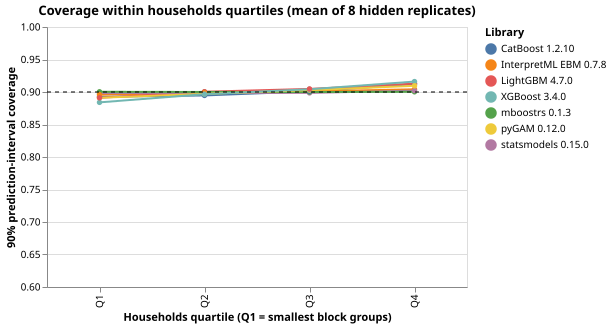

In [12]:
long = (p_full.filter(pl.col("ok")).select(["library"] + quartiles)
        .unpivot(index="library", variable_name="quartile", value_name="coverage")
        .group_by("library", "quartile").agg(pl.col("coverage").mean())
        .with_columns(pl.col("quartile").str.replace("cov_hh_q", "Q"),
                      pl.col("library").replace(LIBS)))
base = alt.Chart(long.to_pandas())
lines = base.mark_line(point=True).encode(
    x=alt.X("quartile:N", title="Households quartile (Q1 = smallest block groups)"),
    y=alt.Y("coverage:Q", title="90% prediction-interval coverage", scale=alt.Scale(domain=[0.6, 1.0])),
    color=alt.Color("library:N", title="Library"),
)
rule = alt.Chart(pl.DataFrame({"y": [0.9]}).to_pandas()).mark_rule(strokeDash=[4, 4]).encode(y="y:Q")
(lines + rule).properties(width=420, height=260,
                          title="Coverage within households quartiles (mean of 8 hidden replicates)")

## Follow-up speed, robustness and scale (D5, D6)

The follow-up session refits each pipeline's final model ten times on the
15,480 dev rows, dropping one covariate each time. The tree boosters and
statsmodels refit in 0.07 to 0.21 seconds, pyGAM in 0.41 and EBM in 0.75.
mboostrs took 7.9 seconds per refit: its final model is a two-parameter
distributional fit with a spatial tensor surface, a varying coefficient and
1,600 boosting steps, where the others fit a single mean model. On 500,000
rows LightGBM, XGBoost and CatBoost refit in 1 to 4 seconds, pyGAM in 22,
statsmodels in 50, mboostrs in 252 and EBM in 275; every library finished
within the 300-second limit.

The robustness rule (D6) fixed in advance that the small-sample prediction
error should stay within twice the full-sample error. With 800 training
rows against 15,480, every library's error more than doubled (ratios 2.1 to
2.6 for the five without extreme predictions), so the rule gives every
library a 2 and does not separate them. mboostrs scores 1 because three of
its runs failed.

In [13]:
def secs(lib, key):
    entry = runlogs[lib].get(key) or {}
    return entry

speed = []
for lib in LIBS:
    fu = runlogs[lib].get("followup", {})
    times = fu.get("times") or []
    ln = runlogs[lib].get("large_n", {})
    runs = [runlogs[lib][r]["seconds"] for r in REPS if runlogs[lib].get(r, {}).get("ok")]
    speed.append({
        "library": LIBS[lib],
        "followup_median": float(np.median(times)) if times else None,
        "followup_p90": float(np.quantile(times, 0.9)) if times else None,
        "followup_errors": len(fu.get("errors") or []),
        "large_n_s": ln.get("seconds"),
        "large_n_ok": bool(ln.get("ok")),
        "pipeline_median_s": float(np.median(runs)) if runs else None,
    })
speed = pl.DataFrame(speed)
GT(speed, rowname_col="library").tab_header(
    title="Follow-up refits and scale",
    subtitle="Seconds of wall-clock time, one library at a time, 4 threads") \
    .tab_spanner("10 follow-up refits (15,480 rows, one covariate dropped each)",
                 ["followup_median", "followup_p90", "followup_errors"]) \
    .tab_spanner("500,000-row refit", ["large_n_s", "large_n_ok"]) \
    .cols_label(followup_median="Median", followup_p90="90th pct", followup_errors="Errors",
                large_n_s="Seconds", large_n_ok="Finished", pipeline_median_s="Full pipeline, median") \
    .fmt_number(["followup_median", "followup_p90", "large_n_s", "pipeline_median_s"], decimals=1) \
    .sub_missing(missing_text="failed") \
    .tab_source_note("The full pipeline (tuning, screening, intervals) ran two to four libraries at a "
                     "time on 10 cores, so its times are indicative; the follow-up and large-n "
                     "columns ran alone.")

GT(_tbl_data=shape: (7, 7)
┌──────────────┬──────────────┬──────────────┬─────────────┬────────────┬────────────┬─────────────┐
│ library      ┆ followup_med ┆ followup_p90 ┆ followup_er ┆ large_n_s  ┆ large_n_ok ┆ pipeline_me │
│ ---          ┆ ian          ┆ ---          ┆ rors        ┆ ---        ┆ ---        ┆ dian_s      │
│ str          ┆ ---          ┆ f64          ┆ ---         ┆ f64        ┆ bool       ┆ ---         │
│              ┆ f64          ┆              ┆ i64         ┆            ┆            ┆ f64         │
╞══════════════╪══════════════╪══════════════╪═════════════╪════════════╪════════════╪═════════════╡
│ mboostrs     ┆ 7.862075     ┆ 8.106094     ┆ 0           ┆ 251.865814 ┆ true       ┆ 247.243895  │
│ 0.1.3        ┆              ┆              ┆             ┆            ┆            ┆             │
│ XGBoost      ┆ 0.129362     ┆ 0.14137      ┆ 0           ┆ 2.055798   ┆ true       ┆ 75.301617   │
│ 3.4.0        ┆              ┆              ┆             ┆            ┆            ┆             │
│ LightGBM     ┆ 0.142559     ┆ 0.148333     ┆ 0           ┆ 1.100531   ┆ true       ┆ 138.245215  │
│ 4.7.0        ┆              ┆              ┆             ┆            ┆            ┆             │
│ CatBoost     ┆ 0.213667     ┆ 0.232839     ┆ 0           ┆ 4.094037   ┆ true       ┆ 55.184543   │
│ 1.2.10       ┆              ┆              ┆             ┆            ┆            ┆             │
│ InterpretML  ┆ 0.745411     ┆ 0.866412     ┆ 0           ┆ 274.676382 ┆ true       ┆ 96.344862   │
│ EBM 0.7.8    ┆              ┆              ┆             ┆            ┆            ┆             │
│ pyGAM 0.12.0 ┆ 0.409332     ┆ 0.417087     ┆ 0           ┆ 21.663004  ┆ true       ┆ 161.200631  │
│ statsmodels  ┆ 0.070114     ┆ 0.098684     ┆ 0           ┆ 49.905012  ┆ true       ┆ 45.694627   │
│ 0.15.0       ┆              ┆              ┆             ┆            ┆            ┆             │
└──────────────┴──────────────┴──────────────┴─────────────┴────────────┴────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x128c040e0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='followup_median', type=<ColInfoTypeEnum.default: 1>, column_label='Median', column_align='right', column_width=None), ColInfo(var='followup_p90', type=<ColInfoTypeEnum.default: 1>, column_label='90th pct', column_align='right', column_width=None), ColInfo(var='followup_errors', type=<ColInfoTypeEnum.default: 1>, column_label='Errors', column_align='right', column_width=None), ColInfo(var='large_n_s', type=<ColInfoTypeEnum.default: 1>, column_label='Seconds', column_align='right', column_width=None), ColInfo(var='large_n_ok', type=<ColInfoTypeEnum.default: 1>, column_label='Finished', column_align='center', column_width=None), ColInfo(var='pipeline_median_s', type=<ColInfoTypeEnum.default: 1>, column_label='Full pipeline, median', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1248ac5c0>, _spanners=Spanners([SpannerInfo(spanner_id='10 follow-up refits (15,480 rows, one covariate dropped each)', spanner_level=0, spanner_label='10 follow-up refits (15,480 rows, one covariate dropped each)', spanner_units=None, spanner_pattern=None, vars=['followup_median', 'followup_p90', 'followup_errors'], built=None), SpannerInfo(spanner_id='500,000-row refit', spanner_level=0, spanner_label='500,000-row refit', spanner_units=None, spanner_pattern=None, vars=['large_n_s', 'large_n_ok'], built=None)]), _heading=Heading(title='Follow-up refits and scale', subtitle='Seconds of wall-clock time, one library at a time, 4 threads', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x117bd1100>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x128e5f980>, _source_notes=['The full pipeline (tuning, screening, intervals) ran two to four li

## Reproducibility (D10)

Every pipeline is deterministic: the grader's two dev runs gave identical
findings and identical predictions for all seven libraries, and each
analyst's own dev output matched the grader's rerun. mboostrs's predictions
differed from its analyst's by at most 8 × 10⁻¹⁴, the size of
floating-point rounding when a computation runs on a different number of
threads (the analyst ran with 2, the grader with 4); the scorecard treats
differences below 10⁻⁹ as a match. Every analyst kept a tuning log (EBM's
is in `dev_out/`). None recorded data or environment hashes, which the
scorecard's top anchor asks for.

In [14]:
rep_rows = []
for lib in LIBS:
    g = runlogs[lib].get("repro_grader_vs_grader", {})
    a = runlogs[lib].get("repro_grader_vs_analyst", {})
    log_path = next((p for p in (ROOT / "runs" / lib / "tuning_log.csv",
                                 ROOT / "runs" / lib / "dev_out" / "tuning_log.csv") if p.exists()),
                    ROOT / "runs" / lib / "tuning_log.csv")
    rep_rows.append({
        "library": LIBS[lib],
        "rerun_findings_equal": g.get("findings_equal"),
        "rerun_pred_diff": g.get("pred_max_abs_diff"),
        "analyst_findings_equal": a.get("findings_equal"),
        "analyst_pred_diff": a.get("pred_max_abs_diff"),
        "tuning_log_rows": pl.read_csv(log_path).height if log_path.exists() else 0,
    })
repro = pl.DataFrame(rep_rows, infer_schema_length=None).with_columns(
    pl.col("rerun_findings_equal").cast(pl.String), pl.col("analyst_findings_equal").cast(pl.String),
    pl.col("rerun_pred_diff").cast(pl.String), pl.col("analyst_pred_diff").cast(pl.String))
GT(repro, rowname_col="library").tab_header(
    title="Reproducibility of the dev run",
    subtitle="Grader reran run.py twice with seed 1; compared with each other and with the analyst's dev_out") \
    .tab_spanner("Grader run 1 vs run 2", ["rerun_findings_equal", "rerun_pred_diff"]) \
    .tab_spanner("Grader vs analyst", ["analyst_findings_equal", "analyst_pred_diff"]) \
    .cols_label(rerun_findings_equal="findings.json equal", rerun_pred_diff="Max prediction difference",
                analyst_findings_equal="findings.json equal", analyst_pred_diff="Max prediction difference",
                tuning_log_rows="Tuning log rows")

GT(_tbl_data=shape: (7, 6)
┌────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ library        ┆ rerun_findings ┆ rerun_pred_dif ┆ analyst_findi ┆ analyst_pred_ ┆ tuning_log_ro │
│ ---            ┆ _equal         ┆ f              ┆ ngs_equal     ┆ diff          ┆ ws            │
│ str            ┆ ---            ┆ ---            ┆ ---           ┆ ---           ┆ ---           │
│                ┆ str            ┆ str            ┆ str           ┆ str           ┆ i64           │
╞════════════════╪════════════════╪════════════════╪═══════════════╪═══════════════╪═══════════════╡
│ mboostrs 0.1.3 ┆ true           ┆ 0.0            ┆ true          ┆ 8.26005930321 ┆ 25            │
│                ┆                ┆                ┆               ┆ 1165e-14      ┆               │
│ XGBoost 3.4.0  ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 14            │
│ LightGBM 4.7.0 ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 23            │
│ CatBoost       ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 14            │
│ 1.2.10         ┆                ┆                ┆               ┆               ┆               │
│ InterpretML    ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 27            │
│ EBM 0.7.8      ┆                ┆                ┆               ┆               ┆               │
│ pyGAM 0.12.0   ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 35            │
│ statsmodels    ┆ true           ┆ 0.0            ┆ true          ┆ 0.0           ┆ 24            │
│ 0.15.0         ┆                ┆                ┆               ┆               ┆               │
└────────────────┴────────────────┴────────────────┴───────────────┴───────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x123df8fe0>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='rerun_findings_equal', type=<ColInfoTypeEnum.default: 1>, column_label='findings.json equal', column_align='left', column_width=None), ColInfo(var='rerun_pred_diff', type=<ColInfoTypeEnum.default: 1>, column_label='Max prediction difference', column_align='left', column_width=None), ColInfo(var='analyst_findings_equal', type=<ColInfoTypeEnum.default: 1>, column_label='findings.json equal', column_align='left', column_width=None), ColInfo(var='analyst_pred_diff', type=<ColInfoTypeEnum.default: 1>, column_label='Max prediction difference', column_align='left', column_width=None), ColInfo(var='tuning_log_rows', type=<ColInfoTypeEnum.default: 1>, column_label='Tuning log rows', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1293f79b0>, _spanners=Spanners([SpannerInfo(spanner_id='Grader run 1 vs run 2', spanner_level=0, spanner_label='Grader run 1 vs run 2', spanner_units=None, spanner_pattern=None, vars=['rerun_findings_equal', 'rerun_pred_diff'], built=None), SpannerInfo(spanner_id='Grader vs analyst', spanner_level=0, spanner_label='Grader vs analyst', spanner_units=None, spanner_pattern=None, vars=['analyst_findings_equal', 'analyst_pred_diff'], built=None)]), _heading=Heading(title='Reproducibility of the dev run', subtitle="Grader reran run.py twice with seed 1; compared with each other and with the analyst's dev_out", preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x128321820>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x12939b440>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x1293f5730>, _formats=[], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scs

## The analysts' effort, reports and friction (D2, D3, D7, D8)

The mboostrs analyst had never seen the library and learned it from
`mboostrs.agent_guide()` and the package source; it did not open the book.
It used the most tokens of the seven (459,000, against 233,000 to 345,000)
and the most time. It still reached the library's distributional model, its
interaction screen, its specification comparison with the
two-standard-error rule and its REML refits, which it could only have found
through the guide. Its friction log records what the guide did not tell it:
that `na_action="impute"` exists (it wrote its own imputation), and that
`gamlss_refit` mishandled string category labels (it recoded the roof
classes as integers). The other six analysts relied on what they already
knew about their libraries, `help()` and the installed source; only the
LightGBM analyst fetched the online documentation, twice.

Every tree-library analyst wrote partial dependence, permutation tests,
interaction tests, a spread model and conformal intervals by hand, because
their libraries provide none of them for this purpose. Their friction logs
list the error messages they met; the judged scores below quote them.

In [15]:
GT(agents, rowname_col="library").tab_header(
    title="What each analyst spent",
    subtitle="Claude Haiku agents, one per library, no assists after launch") \
    .cols_label(tokens="Tokens", tool_calls="Tool calls", minutes="Elapsed minutes",
                report_file="REPORT.md written", friction_file="FRICTION.md written",
                documentation="Documentation used") \
    .fmt_integer(["tokens"]).fmt_number(["minutes"], decimals=0) \
    .sub_missing(missing_text="not reported") \
    .tab_source_note("The agent harness refused report-file writes from five analysts; their report "
                     "text came back in their final message and was saved unchanged as "
                     "runs/<library>/REPORT.md.")

GT(_tbl_data=shape: (7, 7)
┌────────────────┬────────┬────────────┬─────────┬────────────────┬────────────────┬───────────────┐
│ library        ┆ tokens ┆ tool_calls ┆ minutes ┆ report_file    ┆ friction_file  ┆ documentation │
│ ---            ┆ ---    ┆ ---        ┆ ---     ┆ ---            ┆ ---            ┆ ---           │
│ str            ┆ i64    ┆ i64        ┆ i64     ┆ str            ┆ str            ┆ str           │
╞════════════════╪════════╪════════════╪═════════╪════════════════╪════════════════╪═══════════════╡
│ mboostrs 0.1.3 ┆ 459003 ┆ 212        ┆ 52      ┆ yes            ┆ yes            ┆ agent_guide() │
│                ┆        ┆            ┆         ┆                ┆                ┆ , help(),     │
│                ┆        ┆            ┆         ┆                ┆                ┆ package…      │
│ XGBoost 3.4.0  ┆ 344911 ┆ 281        ┆ 23      ┆ refused (saved ┆ refused (saved ┆ prior         │
│                ┆        ┆            ┆         ┆ from message)  ┆ from message)  ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
│ LightGBM 4.7.0 ┆ 232632 ┆ 77         ┆ 40      ┆ yes            ┆ yes            ┆ prior         │
│                ┆        ┆            ┆         ┆                ┆                ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
│ CatBoost       ┆ 262056 ┆ 78         ┆ 27      ┆ refused (saved ┆ yes            ┆ prior         │
│ 1.2.10         ┆        ┆            ┆         ┆ from message)  ┆                ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
│ InterpretML    ┆ 257309 ┆ 69         ┆ 39      ┆ refused (saved ┆ refused (saved ┆ prior         │
│ EBM 0.7.8      ┆        ┆            ┆         ┆ from message)  ┆ from message)  ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
│ pyGAM 0.12.0   ┆ 298657 ┆ null       ┆ 47      ┆ refused (saved ┆ yes            ┆ prior         │
│                ┆        ┆            ┆         ┆ from message)  ┆                ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
│ statsmodels    ┆ 333452 ┆ 118        ┆ 33      ┆ refused (saved ┆ yes            ┆ prior         │
│ 0.15.0         ┆        ┆            ┆         ┆ from message)  ┆                ┆ knowledge,    │
│                ┆        ┆            ┆         ┆                ┆                ┆ help(),       │
│                ┆        ┆            ┆         ┆                ┆                ┆ insta…        │
└────────────────┴────────┴────────────┴─────────┴────────────────┴────────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x12475c470>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='tokens', type=<ColInfoTypeEnum.default: 1>, column_label='Tokens', column_align='right', column_width=None), ColInfo(var='tool_calls', type=<ColInfoTypeEnum.default: 1>, column_label='Tool calls', column_align='right', column_width=None), ColInfo(var='minutes', type=<ColInfoTypeEnum.default: 1>, column_label='Elapsed minutes', column_align='right', column_width=None), ColInfo(var='report_file', type=<ColInfoTypeEnum.default: 1

In [16]:
jrows = []
for d in ["D2", "D3", "D7", "D8"]:
    for lib in LIBS:
        jrows.append({"dimension": f"{d} {names[d]}", "library": LIBS[lib],
                      "score": JUDGED[lib][d]["score"], "evidence": JUDGED[lib][d]["evidence"]})
GT(pl.DataFrame(jrows), rowname_col="library", groupname_col="dimension").tab_header(
    title="Judged dimensions and their evidence",
    subtitle="Scored by the coordinator from REPORT text, FRICTION.md and run.py against the scorecard anchors") \
    .fmt_number(["score"], decimals=1)

GT(_tbl_data=shape: (28, 4)
┌───────────────────────┬───────────────────────┬───────┬─────────────────────────────────┐
│ dimension             ┆ library               ┆ score ┆ evidence                        │
│ ---                   ┆ ---                   ┆ ---   ┆ ---                             │
│ str                   ┆ str                   ┆ f64   ┆ str                             │
╞═══════════════════════╪═══════════════════════╪═══════╪═════════════════════════════════╡
│ D2 Causal humility    ┆ mboostrs 0.1.3        ┆ 4.0   ┆ Report opens 'These are associ… │
│ D2 Causal humility    ┆ XGBoost 3.4.0         ┆ 2.0   ┆ Report: 'These are association… │
│ D2 Causal humility    ┆ LightGBM 4.7.0        ┆ 2.0   ┆ Report: 'These are association… │
│ D2 Causal humility    ┆ CatBoost 1.2.10       ┆ 2.0   ┆ Report: 'The data cannot estab… │
│ D2 Causal humility    ┆ InterpretML EBM 0.7.8 ┆ 2.0   ┆ Report lists 'causal effects' … │
│ …                     ┆ …                     ┆ …     ┆ …                               │
│ D8 Agent-friendliness ┆ LightGBM 4.7.0        ┆ 2.5   ┆ Completed every deliverable. A… │
│ D8 Agent-friendliness ┆ CatBoost 1.2.10       ┆ 3.0   ┆ Completed every deliverable it… │
│ D8 Agent-friendliness ┆ InterpretML EBM 0.7.8 ┆ 3.0   ┆ Completed every deliverable it… │
│ D8 Agent-friendliness ┆ pyGAM 0.12.0          ┆ 2.5   ┆ Completed every deliverable it… │
│ D8 Agent-friendliness ┆ statsmodels 0.15.0    ┆ 3.0   ┆ Completed every deliverable it… │
└───────────────────────┴───────────────────────┴───────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x1248af020>, _boxhead=Boxhead([ColInfo(var='dimension', type=<ColInfoTypeEnum.row_group: 3>, column_label='dimension', column_align='left', column_width=None), ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None), ColInfo(var='score', type=<ColInfoTypeEnum.default: 1>, column_label='score', column_align='right', column_width=None), ColInfo(var='evidence', type=<ColInfoTypeEnum.default: 1>, column_label='evidence', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1293b3dd0>, _spanners=Spanners([]), _heading=Heading(title='Judged dimensions and their evidence', subtitle='Scored by the coordinator from REPORT text, FRICTION.md and run.py against the scorecard anchors', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x129424920>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x129424710>, _source_notes=[], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x129424380>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1294247a0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table

## Scorecard

The scorecard grades each library from 1 to 5 on the ten dimensions of
`docs/scorecard/scorecard.md`. Six dimensions apply the thresholds of the
protocol to the measurements above; four are judged, with the evidence in
the table that follows. Two scoring decisions affect mboostrs. First, the
protocol scores a failed run as making no claims; on the null replicates
that would score mboostrs's crashes as clean results, so a null replicate
that did not run counts as failing the null condition (mboostrs D1 is 2;
the literal rule would give 5). Second, a failed run counts as zero coverage
on its replicate, so mboostrs's prediction coverage over all eight hidden
replicates is 0.79 and its D9 is 2, although its seven completed runs are
the best calibrated of any library.

By the scorecard's weights, statsmodels has the highest aggregate in both
modes (3.48 fully automated, 3.24 semi-automated) and mboostrs the lowest in
fully automated mode (2.95). The per-dimension profile records mboostrs's higher judged scores alongside
its lower robustness and speed scores. Failed runs also lower its discovery
and prediction-coverage scores, as defined above.

In [17]:
def d1(lib, literal=False):
    # Protocol: a failed run scores as no claims. On a null replicate that
    # would score a crash as a clean pass, so (literal=False) a null replicate
    # that did not run leaves the null condition unmet.
    f = full.filter(pl.col("library") == lib)
    n = null.filter(pl.col("library") == lib)
    tpr, fdr = f["mean_tpr"].mean(), f["mean_fdr"].mean()
    if n["ok"].all() or literal:
        nf = n["n_false"].mean()
    else:
        nf = float("inf")
    if not f["ok"].any():
        return 1.0
    if tpr < 0.75 or fdr > 0.25 or nf > 1:
        return 2.0
    pair = f["pair_tpr"].mean() >= 0.5 and f["pair_fdr"].mean() <= 0.5
    scale = f["scale_tpr"].mean() >= 0.5 and f["scale_fdr"].mean() <= 0.5
    both = (f["pair_tpr"].mean() >= 0.5 and f["scale_tpr"].mean() >= 0.5
            and f["pair_fdr"].mean() <= 0.34 and f["scale_fdr"].mean() <= 0.34)
    return 5.0 if both else 4.0 if (pair or scale) else 3.0


def d4(lib):
    q = q_full.filter(pl.col("library") == lib)
    if not q["has_interval"].any():
        return 1.0
    c = q["covered"].mean()
    return 2.0 if c < 0.70 else 3.0 if (c < 0.82 or c > 0.98) else 4.0


def d5(lib):
    t = runlogs[lib].get("followup", {}).get("times") or []
    if not t:
        return 1.0
    m = float(np.median(t))
    return 1.0 if m > 60 else 2.0 if m > 10 else 3.0 if m > 1 else 4.0


def d6(lib):
    if failures(lib):
        return 1.0
    s = small.filter(pl.col("library") == lib)
    ps = preds.filter((pl.col("library") == lib) & (pl.col("kind") == "small"))["rmse_f"].mean()
    pf = p_full.filter(pl.col("library") == lib)["rmse_f"].mean()
    if s["mean_fdr"].mean() > 0.5 or ps > 2 * pf:
        return 2.0
    return 4.0 if runlogs[lib].get("large_n", {}).get("ok") and (runlogs[lib]["large_n"].get("seconds") or 1e9) <= 300 else 3.0


def d9(lib):
    # Protocol: a failed run has no intervals, so it covers nothing on that
    # replicate (coverage 0) and the overall coverage is the mean over all 8.
    p = p_full.filter(pl.col("library") == lib)
    if not p.filter(pl.col("ok"))["has_pi"].fill_null(False).any():
        return 1.0
    c = p["cov90"].fill_null(0.0).mean()
    if not 0.86 <= c <= 0.94:
        return 2.0
    worst = [p[q].fill_null(0.0).mean() for q in quartiles]
    return 4.0 if all(0.84 <= w <= 0.96 for w in worst) else 3.0


TOL = 1e-9  # "matches": equal findings and predictions equal to floating-point noise


def tuning_log(lib):
    for path in (ROOT / "runs" / lib / "tuning_log.csv", ROOT / "runs" / lib / "dev_out" / "tuning_log.csv"):
        if path.exists():
            return path
    return None


def d10(lib):
    g = runlogs[lib].get("repro_grader_vs_grader", {})
    a = runlogs[lib].get("repro_grader_vs_analyst", {})
    same = g.get("findings_equal") is True and g.get("pred_max_abs_diff") == 0.0
    if not same:
        return 1.0
    if tuning_log(lib) is None:
        return 2.0
    diff = a.get("pred_max_abs_diff")
    matches = a.get("findings_equal") is True and isinstance(diff, float) and diff < TOL
    return 4.0 if matches else 3.0


measured = {"D1": d1, "D4": d4, "D5": d5, "D6": d6, "D9": d9, "D10": d10}
W_AUTO = {"D1": 2, "D2": 1, "D3": 2, "D4": 1, "D5": 2, "D6": 1, "D7": 0.5, "D8": 2, "D9": 2, "D10": 1}
W_SEMI = {"D1": 2, "D2": 1, "D3": 1, "D4": 2, "D5": 1, "D6": 1, "D7": 2, "D8": 0.5, "D9": 1, "D10": 1}
sheet = []
for d in dims:
    row = {"dimension": f"{d} {names[d]}", "basis": "measured" if d in measured else "judged"}
    for lib in LIBS:
        row[lib] = measured[d](lib) if d in measured else JUDGED[lib][d]["score"]
    sheet.append(row)
for label, w in (("Weighted, fully automated", W_AUTO), ("Weighted, semi-automated", W_SEMI)):
    row = {"dimension": label, "basis": "aggregate"}
    for lib in LIBS:
        row[lib] = sum(w[r["dimension"].split()[0]] * r[lib] for r in sheet[:10]) / sum(w.values())
    sheet.append(row)
scorecard = pl.DataFrame(sheet)
gt = (GT(scorecard, rowname_col="dimension")
      .tab_header(title="Knowledge-discovery scorecard (docs/scorecard/scorecard.md)",
                  subtitle="1-5 per dimension; measured rows apply the pre-registered thresholds, "
                           "judged rows are argued in the table below")
      .cols_label(basis="Basis", **LIBS)
      .fmt_number(list(LIBS), decimals=1)
      .tab_source_note("Weights from the scorecard's mode table. The aggregates are shown only with "
                       "the profile above them; two libraries can reach one aggregate by very "
                       "different profiles."))
for i, r in enumerate(sheet[:10]):
    vals = [r[lib] for lib in LIBS]
    winners = [lib for lib in LIBS if r[lib] == max(vals)]
    gt = gt.tab_style(style.text(weight="bold"), loc.body(columns=winners, rows=[i]))
gt

GT(_tbl_data=shape: (12, 9)
┌─────────────┬───────────┬──────────┬──────────┬───┬──────────┬──────────┬──────────┬─────────────┐
│ dimension   ┆ basis     ┆ mboostrs ┆ xgboost  ┆ … ┆ catboost ┆ ebm      ┆ pygam    ┆ statsmodels │
│ ---         ┆ ---       ┆ ---      ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---      ┆ ---         │
│ str         ┆ str       ┆ f64      ┆ f64      ┆   ┆ f64      ┆ f64      ┆ f64      ┆ f64         │
╞═════════════╪═══════════╪══════════╪══════════╪═══╪══════════╪══════════╪══════════╪═════════════╡
│ D1 Relation ┆ measured  ┆ 2.0      ┆ 4.0      ┆ … ┆ 4.0      ┆ 4.0      ┆ 4.0      ┆ 4.0         │
│ ship        ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ discovery   ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D2 Causal   ┆ judged    ┆ 4.0      ┆ 2.0      ┆ … ┆ 2.0      ┆ 2.0      ┆ 2.0      ┆ 3.0         │
│ humility    ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D3          ┆ judged    ┆ 4.5      ┆ 3.0      ┆ … ┆ 3.0      ┆ 3.5      ┆ 3.5      ┆ 4.0         │
│ Explanation ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ quality     ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D4          ┆ measured  ┆ 2.0      ┆ 2.0      ┆ … ┆ 2.0      ┆ 2.0      ┆ 3.0      ┆ 2.0         │
│ Importance  ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ quantificat ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ ion         ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D5          ┆ measured  ┆ 3.0      ┆ 4.0      ┆ … ┆ 4.0      ┆ 4.0      ┆ 4.0      ┆ 4.0         │
│ Iteration   ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ speed       ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ …           ┆ …         ┆ …        ┆ …        ┆ … ┆ …        ┆ …        ┆ …        ┆ …           │
│ D8 Agent-fr ┆ judged    ┆ 3.5      ┆ 3.0      ┆ … ┆ 3.0      ┆ 3.0      ┆ 2.5      ┆ 3.0         │
│ iendliness  ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D9          ┆ measured  ┆ 2.0      ┆ 4.0      ┆ … ┆ 4.0      ┆ 4.0      ┆ 4.0      ┆ 4.0         │
│ Uncertainty ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ honesty     ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ D10 Reprodu ┆ measured  ┆ 4.0      ┆ 4.0      ┆ … ┆ 4.0      ┆ 4.0      ┆ 4.0      ┆ 4.0         │
│ cibility    ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ Weighted,   ┆ aggregate ┆ 2.948276 ┆ 3.275862 ┆ … ┆ 3.258621 ┆ 3.344828 ┆ 3.327586 ┆ 3.482759    │
│ fully       ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ automated   ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ Weighted,   ┆ aggregate ┆ 2.82     ┆ 3.08     ┆ … ┆ 3.0      ┆ 3.12     ┆ 3.18     ┆ 3.24        │
│ semi-automa ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
│ ted         ┆           ┆          ┆          ┆   ┆          ┆          ┆          ┆             │
└─────────────┴───────────┴──────────┴──────────┴───┴──────────┴──────────┴──────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x1293b1070>, _boxhead=Boxhead([ColInfo(var='dimension', type=<ColInfoTypeEnum.stub: 2>, column_label='dimension', column_align='left', column_width=None), ColInfo(var='basis', type=<ColInfoTypeEnum.default: 1>, column_label='Basis', column_align='left', column_width=None), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs 0.1.3', column_align='right', colum

(where-other-libraries-did-better)=
## Other libraries: results and workflows

- **The tree boosters (XGBoost, LightGBM, CatBoost)** never failed a run,
  refit in a fraction of a second, and fit 500,000 rows in 1 to 4 seconds.
  Their analysts built calibrated, spread-adaptive prediction intervals
  from tools the libraries do not provide, and those intervals cover as
  well as mboostrs's (0.884 to 0.916 in every quartile). XGBoost and
  LightGBM made no false claim on the null replicates.
- **EBM** found the age × income interaction on all eight replicates, the
  only library to do so, made no false mean-effect claim, and had the
  second most accurate predictions (RMSE 0.069).
- **pyGAM** completed every run with no false mean effect, households alone as the spread
  driver, no claims on null data, and the best effect-interval coverage
  among them (0.78). Its analyst clipped test covariates to the training
  range, which kept its small-sample predictions within 0.9 of the truth
  where mboostrs's and statsmodels' were not.
- **statsmodels** refit fastest (0.07 seconds), finished every run, and has
  the highest weighted score; its result objects carry tests and intervals
  that an analyst can report directly.
- Six of the seven analysts checked their own pipeline on a permuted
  outcome before delivering it. That check is what the mboostrs pipeline
  lacked.

## Opportunities for mboostrs

The run points at seven changes, ranked by how much they would have moved
the scores. The first five are in the pull request that accompanies this
page (see the changelog); the last two are open.

1. **Discoverable API guidance.** The guide was 39 KB in one piece and said nothing about
   missing values or intervals. It now has topic sections
   (`agent_guide("missing-data")`, `"uncertainty"`, `"categoricals"`,
   `"costs"`, `"unattended-pipelines"`), each with an example the test suite
   runs, and `python -m mboostrs skill install` puts it where coding agents
   load skills automatically. Its statement that no intervals or p-values
   exist was wrong and is corrected.
2. **Empty selections.** A selection step that drops every term must lead
   to `"y ~ 1"`. The error for `"y ~ "` now says so, and the
   `unattended-pipelines` topic tells agents to handle the empty case and to
   run the pipeline on a permuted outcome before trusting it.
3. **String categories in the refits and intervals.** `gamlss_refit`,
   `confint(method="refit")`, `LSSModel.prediction_interval(newdata=...)` and
   `conformal_interval` all failed on string category labels; all four are
   fixed. The error that suggested `unseen_levels="zero_effect"` (which
   would have zeroed the roof effect) now says the frame is coded
   differently.
4. **Missing values in distributional models.** `gamboostLSS` and
   `glmboostLSS` take `na_action="impute"` and `"omit"` as `gamboost` does,
   and `gam_refit`, `gamlss_refit` and `confint(method="refit")` accept an
   imputed model.
5. **Error messages that name the remedy.** A missing predictor value's
   error now names `na_action="impute"`.
6. **Extrapolation (open).** The default `extrapolation="warn"` lets a
   spline continue along its edge slope at any distance, and a `by=` term
   multiplies that by another covariate. On the 800-row replicates this
   produced predictions wrong by up to 262. A default that clips beyond a
   stated distance, or a `by=` term that refuses an unbounded product,
   would have prevented it.
7. **Speed of distributional fits (open).** Follow-up refits took 7.9
   seconds against at most 0.75 for every other library, and one full
   replicate (H2) exceeded 10 minutes even run alone, because its REML
   refit took 536 seconds against about two minutes elsewhere. Distributional
   specification comparisons were the analyst's largest cost
   (`compare_specifications` with `GaussianLSS`: 136 seconds for 14
   candidates). Cost estimates before a long call, and faster LSS fits with
   tensor and varying-coefficient terms, are the work left.

## Departures from the protocol

- **Report files.** The agent harness refused report-file writes from five
  analysts (XGBoost, CatBoost, EBM, pyGAM, statsmodels; XGBoost and EBM also
  lost `FRICTION.md`). The harness's `Write` tool returned "Subagents should
  return findings as text, not write report files" to every subagent writing
  a report-like file; the mboostrs and LightGBM analysts wrote theirs through
  a shell command, which the guard does not check. The five put the text in
  their final message instead. The coordinator saved that text, unchanged,
  as `runs/<library>/REPORT.md` (marked as saved from the message), and the
  full messages are in `claims_discovery/eval/<library>/analyst_message.md`.
  This restriction comes from the agent harness, not from any library.
- **An interruption of the mboostrs analyst.** About 50 minutes into the
  run, the coordinator switched its own session into a git worktree for
  unrelated work. The two analysts still running inherited that isolation
  and every shell call they made was refused for about three minutes. The
  mboostrs analyst stopped with its pipeline edited but not yet re-run; it
  was resumed with a message saying the fault was the coordinator's and to
  continue where it stopped. The pyGAM analyst was told the same and
  finished without stopping. The fault was the coordinator's, not the
  library's; the mboostrs analyst's elapsed time includes the gap.
- **Timed-out replicate re-run alone.** mboostrs's H2 run timed out while
  four grader lanes ran at once. The protocol runs one library at a time, so
  it was re-run alone with the same 10-minute limit; it timed out again and
  is scored as failed.
- **Grader rerun schedule.** The first grader pass ran two libraries at a
  time; it was restarted with four lanes to finish sooner. Runs already
  completed were kept. Run times are therefore indicative, which is why the
  timing scores use the follow-up and 500,000-row measurements, run alone.

## Caveats

- **One dataset, one analyst per library.** Each library was used once, by
  one agent. A different agent, or the same agent on another day, could make
  different choices; the hidden replicates measure the variance of the
  pipeline over data, not over analysts.
- **Prior knowledge is unequal.** The Haiku analysts know XGBoost, LightGBM,
  CatBoost, pyGAM and statsmodels from training. mboostrs is new, and its
  analyst learned it from the package alone (`agent_guide()` and the source).
  That is the condition a new library faces, and it is part of what D7 and
  D8 measure; it also means the mboostrs result understates what an analyst
  who knows the library would do.
- **The coordinator wrote the brief and maintains mboostrs.** The brief
  asks for spread drivers, interactions and intervals, which mboostrs
  models directly. The comparison set includes the libraries an applied
  statistician would reach for on this problem, and every rule, threshold
  and query was fixed before any analyst ran. The judged dimensions carry
  the coordinator's judgment; their evidence is quoted so it can be checked.
- **Coverage across replicates is coarse.** Eight replicates give 64
  effect-query intervals per library; a coverage of 0.90 has a standard
  error of about 0.04 at that count. Prediction coverage uses 41,280
  test rows per library.
- **The test labels are now published.** This split cannot be reused as a
  fresh test for these libraries.